# 01: one still, step by step (MediaPipe and RTMPose on a real 12 MP phone photo)

Goal: understand exactly how each toolbox is called, what it does to the image internally, which choices change the result, and how long every step takes on this laptop (i7-1165G7, CPU only).

Input: `data/TableTennis1/IMG20261118135303.jpg` (realme GT Neo 3, 2026-11-18, backhand with the paddle in front of the body, whole body in frame). Weights from `models/`. Nothing is written to disk.

Shared code (loading, model wrappers, angles, drawing) lives in `src/pose_tracker/stills.py`; this notebook calls the toolboxes directly where it matters, so every step is visible. Notebook `02_tabletennis1_all_stills.ipynb` runs the same pipeline on all 17 photos.

In [1]:
import os, time
from importlib.metadata import version
import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
import onnxruntime as ort
from PIL import Image
from rtmlib.tools.pose_estimation.pre_processings import bbox_xyxy2cs, top_down_affine
from pose_tracker.stills import (ROOT, COCO, MP33, MP_TO_COCO, EDGES, load_image, MediaPipePose,
                                 make_rtmpose, joint_angles, torso_px, draw_skeleton)

IMG = ROOT / "data/TableTennis1/IMG20261118135303.jpg"

def bench(fns, n=10):
    """Time several functions round-robin (one warm-up each), so CPU clock drift hits all of them
    equally (see section 8). Returns {name: (min_ms, median_ms)}."""
    t = {k: [] for k in fns}
    for f in fns.values():
        f()
    for _ in range(n):
        for k, f in fns.items():
            t0 = time.perf_counter(); f(); t[k].append(1000 * (time.perf_counter() - t0))
    return {k: (min(v), float(np.median(v))) for k, v in t.items()}

def cpu_mhz():
    """Mean current clock over all cores (Linux)."""
    return np.mean([float(l.split(":")[1]) for l in open("/proc/cpuinfo") if l.startswith("cpu MHz")])

print(f"mediapipe {mp.__version__}, rtmlib {version('rtmlib')}, onnxruntime {ort.__version__} "
      f"{ort.get_available_providers()}, opencv {cv2.__version__}, CPU threads {os.cpu_count()}")

mediapipe 1.2.3, rtmlib 0.0.16, onnxruntime 1.32.0 ['AzureExecutionProvider', 'CPUExecutionProvider'], opencv 5.0.0, CPU threads 8


## 1. Loading the photo
Three things to get right before any model runs. None of them raises an error when wrong; the models just return worse keypoints.
- **Orientation.** Phones often store the sensor image unrotated and put the rotation in the EXIF `Orientation` tag. `cv2.imread` applies that tag by default; PIL does not (use `ImageOps.exif_transpose`). A sideways person still gets a skeleton, but a bad one.
- **Channel order.** OpenCV loads BGR. MediaPipe wants RGB (`mp.ImageFormat.SRGB`); rtmlib wants BGR (it was written around OpenCV). Swapped channels degrade the models quietly.
- **Size.** 12.6 MP is far more than either model uses (section 2). Decoding the JPEG alone costs tens of ms.

EXIF orientation tag: 0 (0 or 1 = no rotation needed)


3072x4096 = 12.6 MP, file 3.1 MB, JPEG decode min 108 / median 113 ms


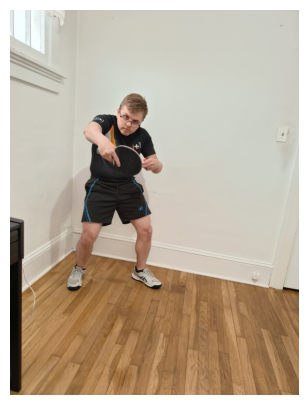

In [2]:
exif = Image.open(IMG).getexif()
print("EXIF orientation tag:", exif.get(274), "(0 or 1 = no rotation needed)")
t_decode = bench({"decode": lambda: cv2.imread(str(IMG))})["decode"]
bgr, _ = load_image(IMG)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
H, W = bgr.shape[:2]
print(f"{W}x{H} = {W*H/1e6:.1f} MP, file {IMG.stat().st_size/1e6:.1f} MB, JPEG decode min {t_decode[0]:.0f} / median {t_decode[1]:.0f} ms")
plt.figure(figsize=(4, 5)); plt.imshow(rgb); plt.axis("off"); plt.show()

## 2. What the two toolboxes do internally
Both are two-stage (find the person, then find the joints inside a crop), but they differ in every detail.

| | MediaPipe Pose Landmarker (full) | RTMPose-m via rtmlib |
|---|---|---|
| Stage 1 | BlazePose detector, 224x224 input, finds the person and an alignment (rotation) | YOLOX-m person detector, 640x640 letterbox, score threshold 0.7, NMS 0.45 |
| Crop | rotated square ROI, resized to 256x256 | box padded by 1.25, aspect forced to 3:4, affine crop to 192x256 (w x h) |
| Stage 2 | regression network, 33 landmarks | SimCC head: each joint's x and y as a 1D classification over bins at 2x the input resolution |
| Output | x, y normalized to [0, 1]; z (relative depth); `visibility`, `presence`; plus metric "world" landmarks (model guess, hip-centered) | x, y in px (17 COCO joints); score = peak of the SimCC distribution |
| Modes | IMAGE (detector every call), VIDEO (tracks the ROI between frames, needs timestamps) | Body: detector every call; PoseTracker: detector every N frames |

Sources: MediaPipe and RTMPose model cards and the RTMPose paper [assumed]. The RTMPose crop size and padding are verified in rtmlib's code (`RTMPose.preprocess`) and shown below.

Consequence: whatever the photo size, each model looks at the person through a crop about 256 px tall. The 12 MP mostly buys nothing for the keypoints, only decode and resize time. Section 7b measures this.

## 3. MediaPipe, step by step
`PoseLandmarker.create_from_options` loads the `.task` bundle (detector + landmark model). In IMAGE mode each `detect` call is independent. The first call is slower (memory allocation, XNNPACK set-up), so time it separately.

In [3]:
t0 = time.perf_counter(); mpp = MediaPipePose(); t_mp_load = 1000 * (time.perf_counter() - t0)
mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
t0 = time.perf_counter(); res = mpp.landmarker.detect(mp_img); t_mp_first = 1000 * (time.perf_counter() - t0)
print(f"load {t_mp_load:.0f} ms, first detect {t_mp_first:.0f} ms")
print("persons:", len(res.pose_landmarks), "| landmarks:", len(res.pose_landmarks[0]),
      "| world landmarks:", len(res.pose_world_landmarks[0]))
print("nose, image coords :", res.pose_landmarks[0][0])
print("nose, world coords :", res.pose_world_landmarks[0][0], "(meters, hip-centered, model estimate)")

load 137 ms, first detect 74 ms
persons: 1 | landmarks: 33 | world landmarks: 33
nose, image coords : NormalizedLandmark(x=0.41415444016456604, y=0.2989422380924225, z=-0.4659823179244995, visibility=0.999996542930603, presence=0.9999926090240479, name=None)
nose, world coords : Landmark(x=0.10703007131814957, y=-0.49082523584365845, z=-0.31641969084739685, visibility=0.999996542930603, presence=0.9999926090240479, name=None) (meters, hip-centered, model estimate)


INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7294380034b0, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x729444002f40, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
W0000 00:00:1795030093.637720   43226 inference_runner_litert.cc:1433] Input tensor memory is not aligned according to LiteRt's memory alignment requirements. Reallocating memory and copying data.
W0000 00:00:1795030093.709276   43226 landmark_projection_calculator.cc:81] Using NORM_RECT without I

About the log lines above: MediaPipe 1.x runs on LiteRT (the TFLite successor) with the XNNPACK CPU delegate. "Sparsity tensors may not yet be fully supported", "Input tensor memory is not aligned ... copying data" (an extra copy of the input, negligible) and "NORM_RECT without IMAGE_DIMENSIONS ... square ROI" are internal and appear for every image; they do not change the result here (the landmarks land on the body, section 5).

The wrapper `MediaPipePose.__call__` does the BGR to RGB conversion and the normalized-to-pixel conversion (`x * W`, `y * H`). MediaPipe gives 33 landmarks; 17 map onto COCO (`MP_TO_COCO`). The extra 16 include hand points (pinky, index, thumb) and foot points (heel, toe), which may help later with paddle-hand orientation and foot placement.

In [4]:
mp_xy, mp_vis = mpp(bgr)
mp17 = mp_xy[MP_TO_COCO]
extra = [i for i in range(33) if i not in MP_TO_COCO]
print("landmarks not in COCO-17:", ", ".join(MP33[i] for i in extra))

landmarks not in COCO-17: left_eye_inner, left_eye_outer, right_eye_inner, right_eye_outer, mouth_left, mouth_right, left_pinky, right_pinky, left_index, right_index, left_thumb, right_thumb, left_heel, right_heel, left_foot_index, right_foot_index


## 4. RTMPose, step by step
`rtmlib.Body` holds two ONNX Runtime sessions. Calling `body(bgr)` runs `det_model` and then `pose_model` on each box. Here the two stages are called separately to see the box and the crop the pose model actually receives.

In [5]:
t0 = time.perf_counter(); body = make_rtmpose(); t_rtm_load = 1000 * (time.perf_counter() - t0)
t0 = time.perf_counter(); bboxes = body.det_model(bgr); t_det_first = 1000 * (time.perf_counter() - t0)
t0 = time.perf_counter(); kpts, scores = body.pose_model(bgr, bboxes=bboxes); t_pose_first = 1000 * (time.perf_counter() - t0)
print(f"load {t_rtm_load:.0f} ms, first detector call {t_det_first:.0f} ms, first pose call {t_pose_first:.0f} ms")
print("boxes (x1, y1, x2, y2):", np.round(bboxes).astype(int).tolist())
rtm_xy, rtm_sc = kpts[0], scores[0]

# Reproduce the crop the pose model sees (rtmlib does this inside pose_model, then normalizes mean/std)
in_w, in_h = body.pose_model.model_input_size
center, scale = bbox_xyxy2cs(np.array(bboxes[0]), padding=1.25)
crop, scale = top_down_affine(body.pose_model.model_input_size, scale, center, bgr)
print(f"crop region {scale[0]:.0f}x{scale[1]:.0f} px of the photo -> model input {in_w}x{in_h}: "
      f"1 model pixel = {scale[1]/in_h:.1f} photo px; SimCC bins (2x) = {scale[1]/in_h/2:.1f} photo px")

load /home/sebas/HobbyProjects/pose-tracker/models/rtmlib/yolox_m_humanart.onnx with onnxruntime backend
load /home/sebas/HobbyProjects/pose-tracker/models/rtmlib/rtmpose_m_body7_256x192.onnx with onnxruntime backend


load 329 ms, first detector call 336 ms, first pose call 50 ms
boxes (x1, y1, x2, y2): [[502, 772, 1766, 3376]]
crop region 2441x3255 px of the photo -> model input 192x256: 1 model pixel = 12.7 photo px; SimCC bins (2x) = 6.4 photo px


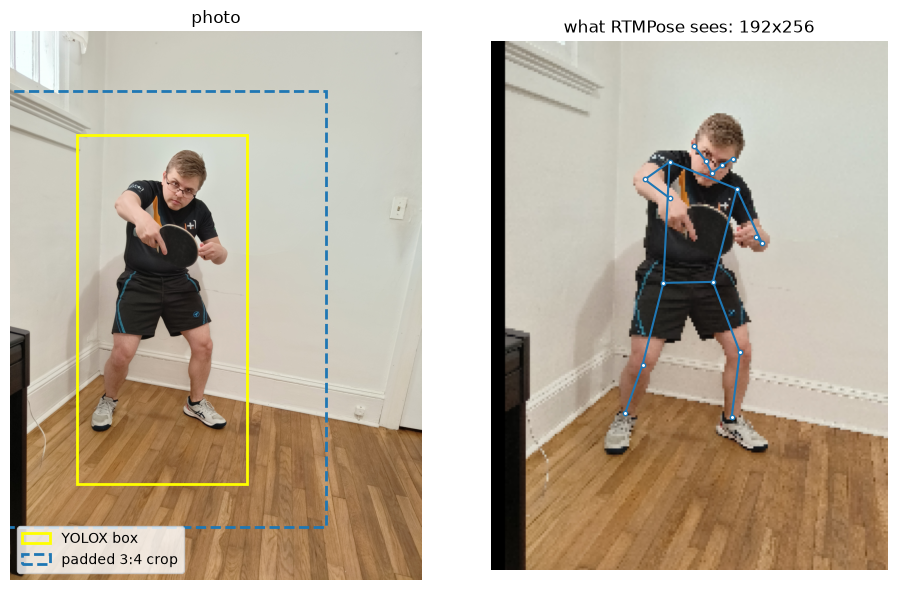

In [6]:
x1, y1, x2, y2 = bboxes[0]
cx, cy = center; sw, sh = scale
fig, axs = plt.subplots(1, 2, figsize=(10, 6), gridspec_kw=dict(width_ratios=[3, 2]))
axs[0].imshow(rgb)
axs[0].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="yellow", lw=2, label="YOLOX box"))
axs[0].add_patch(plt.Rectangle((cx - sw/2, cy - sh/2), sw, sh, fill=False, ec="tab:blue", lw=2, ls="--",
                               label="padded 3:4 crop"))
axs[0].legend(loc="lower left"); axs[0].set_title("photo"); axs[0].axis("off")
axs[1].imshow(cv2.cvtColor(crop.astype(np.uint8), cv2.COLOR_BGR2RGB))
draw_skeleton(axs[1], (rtm_xy - center + scale / 2) / scale * [in_w, in_h], "tab:blue", lw=1.5)
axs[1].set_title(f"what RTMPose sees: {in_w}x{in_h}"); axs[1].axis("off")
plt.tight_layout(); plt.show()

## 5. Both skeletons on the photo
No ground truth here (no tape markers in this set), so the gap between models is **disagreement, not error**. Scale is the torso length (mean shoulder-to-hip, from RTMPose). Scores are listed for orientation only: MediaPipe `visibility` and RTMPose SimCC score are different quantities and must not be compared to each other. The RTMPose score can slightly exceed 1: it is a SimCC peak value, not a probability.

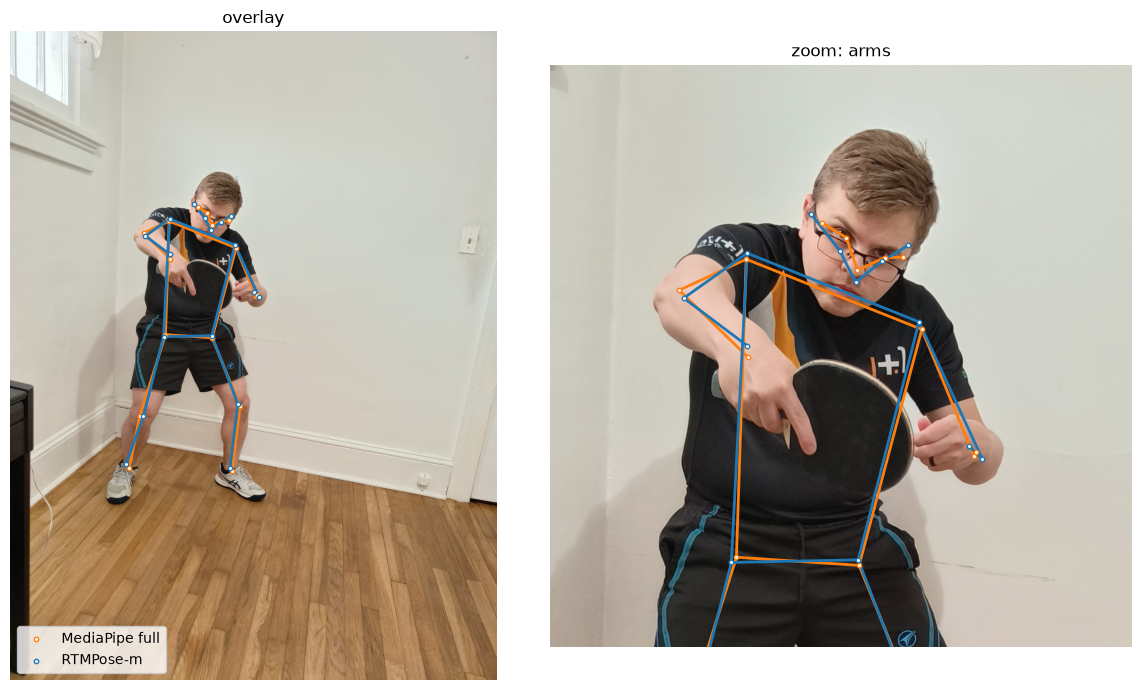

joint       dist_px % torso mp_vis rtm_sc
nose           29.4     4.4   1.00   0.93
l_eye          10.8     1.6   1.00   0.97
r_eye          34.7     5.2   1.00   0.99
l_ear          32.0     4.8   1.00   0.84
r_ear          36.4     5.4   1.00   1.01
l_shoulder     19.2     2.9   1.00   0.91
r_shoulder     14.7     2.2   1.00   0.87
l_elbow        22.6     3.4   1.00   0.81
r_elbow        22.0     3.3   1.00   0.93
l_wrist        21.0     3.1   1.00   0.87
r_wrist        27.9     4.2   0.99   0.86
l_hip          13.5     2.0   1.00   0.81
r_hip          17.6     2.6   1.00   0.81
l_knee         17.1     2.6   1.00   0.96
r_knee         23.2     3.5   1.00   0.88
l_ankle        24.4     3.7   0.99   1.01
r_ankle        34.6     5.2   0.99   0.95
median 22.6 px (3.4 % torso), max 36.4 px (r_ear); torso 668 px


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 7))
for ax in axs:
    ax.imshow(rgb); ax.axis("off")
    draw_skeleton(ax, mp17, "tab:orange", label="MediaPipe full")
    draw_skeleton(ax, rtm_xy, "tab:blue", label="RTMPose-m")
axs[0].legend(loc="lower left"); axs[0].set_title("overlay")
c = np.nanmean(np.r_[mp17[[5, 6, 7, 8, 9, 10]], rtm_xy[[5, 6, 7, 8, 9, 10]]], axis=0)
axs[1].set_xlim(c[0] - 700, c[0] + 700); axs[1].set_ylim(c[1] + 700, c[1] - 700); axs[1].set_title("zoom: arms")
plt.tight_layout(); plt.show()

d = np.linalg.norm(mp17 - rtm_xy, axis=1)
torso = torso_px(rtm_xy)
print(f"{'joint':<11} {'dist_px':>7} {'% torso':>7} {'mp_vis':>6} {'rtm_sc':>6}")
for j, name in enumerate(COCO):
    print(f"{name:<11} {d[j]:7.1f} {100*d[j]/torso:7.1f} {mp_vis[MP_TO_COCO[j]]:6.2f} {rtm_sc[j]:6.2f}")
print(f"median {np.median(d):.1f} px ({100*np.median(d)/torso:.1f} % torso), max {d.max():.1f} px "
      f"({COCO[d.argmax()]}); torso {torso:.0f} px")

## 6. Joint angles (image plane)
Angles are computed in the image plane: they equal the real angle only when the limb segment lies in a plane parallel to the sensor. Names are the **subject's** left and right (COCO convention), so for a person facing the camera, `r_*` appears on the image's left. Sebastian holds the paddle in the right hand.

In [8]:
a_mp, a_rtm = joint_angles(mp17), joint_angles(rtm_xy)
print(f"{'angle':<12} {'MediaPipe':>9} {'RTMPose':>8} {'diff':>6}")
for k in a_mp:
    print(f"{k:<12} {a_mp[k]:9.1f} {a_rtm[k]:8.1f} {a_mp[k]-a_rtm[k]:6.1f}")

angle        MediaPipe  RTMPose   diff
l_elbow           49.8     20.2   29.6
l_shoulder        37.2     39.1   -1.9
l_knee           151.0    151.8   -0.9
r_elbow           69.0     72.2   -3.2
r_shoulder        63.3     51.8   11.6
r_knee           174.0    174.3   -0.3
trunk_lean         7.7      8.0   -0.2


**Angle conditioning.** A 2D angle is unreliable when one of its segments is short in the image (the limb points toward or away from the camera, i.e. foreshortened). A keypoint error of e px on a segment of length L px moves the angle by up to about atan(e/L): with e = 20 px, that is 2 deg for L = 600 px but 22 deg for L = 50 px. Below, image-plane segment lengths as a fraction of torso length (RTMPose). Flag any segment under about 0.3 torso: the angle that uses it should not be trusted.

In [9]:
SEGS = {"l_upper_arm": (5, 7), "l_forearm": (7, 9), "r_upper_arm": (6, 8), "r_forearm": (8, 10),
        "l_thigh": (11, 13), "l_shank": (13, 15), "r_thigh": (12, 14), "r_shank": (14, 16)}
for name, (i, j) in SEGS.items():
    L_rtm, L_mp = np.linalg.norm(rtm_xy[i] - rtm_xy[j]), np.linalg.norm(mp17[i] - mp17[j])
    flag = "  <- short, angle ill-conditioned" if L_rtm / torso < 0.3 else ""
    print(f"{name:<12} RTMPose {L_rtm:5.0f} px ({L_rtm/torso:4.2f} torso)  MediaPipe {L_mp:5.0f} px{flag}")

l_upper_arm  RTMPose   364 px (0.55 torso)  MediaPipe   329 px
l_forearm    RTMPose    45 px (0.07 torso)  MediaPipe    11 px  <- short, angle ill-conditioned
r_upper_arm  RTMPose   187 px (0.28 torso)  MediaPipe   178 px  <- short, angle ill-conditioned
r_forearm    RTMPose   191 px (0.29 torso)  MediaPipe   231 px  <- short, angle ill-conditioned
l_thigh      RTMPose   463 px (0.69 torso)  MediaPipe   465 px
l_shank      RTMPose   404 px (0.60 torso)  MediaPipe   412 px
r_thigh      RTMPose   518 px (0.78 torso)  MediaPipe   542 px
r_shank      RTMPose   318 px (0.48 torso)  MediaPipe   333 px


## 7. Considerations that change the result
### 7a. Determinism
A model run twice on the same image should give identical output. If so, jitter has to be measured on separate photos (the protocol's noise-floor rows), not on repeated runs.

In [10]:
mp_xy2, _ = mpp(bgr)
k2, _ = body(bgr)
print("MediaPipe max diff between two runs:", np.abs(mp_xy2 - mp_xy).max(), "px")
print("RTMPose   max diff between two runs:", np.abs(k2[0] - rtm_xy).max(), "px")

MediaPipe max diff between two runs: 0.0 px
RTMPose   max diff between two runs: 0.0 px


### 7b. Input resolution: does downscaling the photo first change the keypoints, and what does it save?
The photo is resized with `INTER_AREA` (proper anti-aliasing) to a given long side, both models run, and keypoints are mapped back to full-resolution pixels. Shift = median distance over the 17 joints to the full-resolution result of the same model. Times are the min of 5 interleaved runs (see section 8 on why) and include the resize.

In [11]:
sizes = [4096, 2048, 1280, 960, 640, 480]
rows, fns = [], {}
for ls in sizes:
    s = min(1.0, ls / max(H, W))
    prep = lambda s=s: cv2.resize(bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else bgr
    im = prep()
    rows.append((ls, mpp(im)[0][MP_TO_COCO] / s, body(im)[0][0] / s))
    fns[("mp", ls)] = lambda prep=prep: mpp(prep())
    fns[("rtm", ls)] = lambda prep=prep: body(prep())
tt = bench(fns, n=5)
rows = [(ls, a, b, tt[("mp", ls)][0], tt[("rtm", ls)][0]) for ls, a, b in rows]

print(f"{'long side':>9} {'MP shift px':>11} {'RTM shift px':>12} {'MP r_elbow':>10} {'RTM r_elbow':>11} {'MP min ms':>9} {'RTM min ms':>10}")
for ls, a, b, t_mp, t_rtm in rows:
    sa = np.median(np.linalg.norm(a - mp17, axis=1)); sb = np.median(np.linalg.norm(b - rtm_xy, axis=1))
    print(f"{ls:9d} {sa:11.1f} {sb:12.1f} {joint_angles(a)['r_elbow']:10.1f} {joint_angles(b)['r_elbow']:11.1f} {t_mp:9.0f} {t_rtm:10.0f}")
print(f"(torso = {torso:.0f} px at full resolution)")

long side MP shift px RTM shift px MP r_elbow RTM r_elbow MP min ms RTM min ms
     4096         0.0          0.0       69.0        72.2        98        331
     2048         6.8          4.2       72.2        73.3        71        387
     1280         8.0          9.4       66.0        72.4        92        403
      960         9.3          9.7       65.0        71.4       105        439
      640         8.2         11.9       64.2        72.4        85        376
      480         9.6          8.6       62.9        72.2        88        385
(torso = 668 px at full resolution)


### 7c. Low-confidence joints
Rule of thumb thresholds, not calibrated: MediaPipe `visibility` < 0.5, RTMPose score < 0.3. Low values flag occluded or ambiguous joints (here: the paddle arm crossing the body). They are not probabilities of being correct.

In [12]:
low_mp = [COCO[j] for j in range(17) if mp_vis[MP_TO_COCO[j]] < 0.5]
low_rtm = [COCO[j] for j in range(17) if rtm_sc[j] < 0.3]
print("MediaPipe visibility < 0.5:", low_mp or "none")
print("RTMPose score < 0.3       :", low_rtm or "none")

MediaPipe visibility < 0.5: none
RTMPose score < 0.3       : none


### 7d. Left/right consistency
A common failure is a left/right swap, especially in side views and when the arms cross. For a person facing the camera the subject's right shoulder has the smaller x. Check that both models agree on which side is which.

In [13]:
for name, xy in [("MediaPipe", mp17), ("RTMPose", rtm_xy)]:
    print(f"{name:<9}: r_shoulder x = {xy[6,0]:.0f}, l_shoulder x = {xy[5,0]:.0f} -> "
          f"{'facing camera' if xy[6,0] < xy[5,0] else 'back to camera, or swapped'}")

MediaPipe: r_shoulder x = 1005, l_shoulder x = 1427 -> facing camera
RTMPose  : r_shoulder x = 1007, l_shoulder x = 1420 -> facing camera


### 7e. Things the models do not handle
- **The paddle is not a keypoint.** The wrist is the nearest proxy; MediaPipe's hand points (index, pinky, thumb) give a rough hand direction. Paddle tracking is Stage 2.
- **One person.** MediaPipe here returns at most `num_poses=1`; rtmlib returns every YOLOX box above 0.7, and the wrapper keeps the one with the highest mean score.
- **Cropped bodies.** A person cut by the frame edge still gets 17 (or 33) keypoints: the models hallucinate the missing joints, sometimes with confident scores. Check photos where the body leaves the frame by eye.

## 8. Timing summary (this laptop, CPU, 10 interleaved runs after a warm-up)
**How to read these numbers.** During development the same YOLOX call measured 211 ms in one run and 390-570 ms in others, with no code change, and a first version of this cell showed the YOLOX detector alone slower than detector + pose head together. Cause (measured 2026-11-18): the i7-1165G7 runs at about 3.1 GHz for the first seconds of sustained load and falls to about 1.9 GHz within about 15 s (turbo budget / thermal limit; power profile "balanced"), and a browser was using 35-100 % of a core in the background. So a step timed late in a long cell looks slow. Two fixes: all steps are timed **round-robin** (`bench` above), so the drift hits them equally, and both **min** (closest to pure compute at high clock) and **median** (typical on a busy, warm laptop) are reported. The mean clock is printed before and after. Things ruled out: YOLOX time does not depend on the input size (its resize is about 1 ms), rtmlib's `Body` caches nothing, and disabling ONNX Runtime thread spinning made it slower.

In [14]:
mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
mhz0 = cpu_mhz()
t = bench({
    "JPEG decode (cv2.imread, 12.6 MP)": lambda: cv2.imread(str(IMG)),
    "BGR -> RGB": lambda: cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB),
    "MediaPipe detect (full res)": lambda: mpp.landmarker.detect(mp_img),
    "YOLOX-m detector (full res)": lambda: body.det_model(bgr),
    "RTMPose-m pose head, given the box": lambda: body.pose_model(bgr, bboxes=bboxes),
    "RTMPose total: body(bgr)": lambda: body(bgr),
})
print(f"mean CPU clock before {mhz0:.0f} MHz, after {cpu_mhz():.0f} MHz")
print("one-off costs:")
print(f"  MediaPipe model load {t_mp_load:6.0f} ms, first call {t_mp_first:6.0f} ms")
print(f"  rtmlib model load    {t_rtm_load:6.0f} ms, first det {t_det_first:6.0f} ms, first pose {t_pose_first:6.0f} ms")
print(f"per image (warm), ms: {'min':>7} {'median':>7}")
for k, (lo, med) in t.items():
    print(f"  {k:<38} {lo:7.1f} {med:7.1f}")
per_img = t["JPEG decode (cv2.imread, 12.6 MP)"][0] + t["MediaPipe detect (full res)"][0] + t["RTMPose total: body(bgr)"][0]
print(f"decode + both models (min): {per_img:.0f} ms per photo -> 17 photos about {17*per_img/1000:.1f} s")

mean CPU clock before 2200 MHz, after 1500 MHz
one-off costs:
  MediaPipe model load    137 ms, first call     74 ms
  rtmlib model load       329 ms, first det    336 ms, first pose     50 ms
per image (warm), ms:     min  median
  JPEG decode (cv2.imread, 12.6 MP)        139.3   145.4
  BGR -> RGB                                 5.3     6.2
  MediaPipe detect (full res)               45.2    51.1
  YOLOX-m detector (full res)              322.8   490.8
  RTMPose-m pose head, given the box        26.4    46.6
  RTMPose total: body(bgr)                 432.7   462.0
decode + both models (min): 617 ms per photo -> 17 photos about 10.5 s


In [15]:
mpp.close()

INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x7294380034b0, name=CpuAccelerator
INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x729444002f40, name=CpuAccelerator


## Takeaways (one photo, 2026-11-18; timings from 4 runs that day)
- **Calling the toolboxes is two lines each, but the conventions differ.** MediaPipe: `PoseLandmarker.create_from_options(...)`, then `detect(mp.Image(SRGB, rgb))`; gives 33 landmarks, normalized coordinates, `visibility`. rtmlib: `Body(det=..., pose=...)`, then `body(bgr)`; gives 17 COCO joints in pixels and a SimCC score. Get RGB/BGR and normalized/pixel right, and never compare the two confidence values.
- **Resolution: the 12 MP is not used.** RTMPose sees this person at 12.7 photo px per model pixel (192x256 crop), and MediaPipe uses a 256x256 ROI. Downscaling to 2048 px moved keypoints by 4-7 px (about 1 % of torso). It saved no measurable time, because the YOLOX detector always runs at 640x640 and dominates. For stills, keep full resolution. Its cost is about 90-150 ms of JPEG decode.
- **Both models are deterministic** (0.0 px between runs). Jitter must come from separate photos (protocol rows 5 and 6).
- **Agreement:** median 22.6 px between models (3.4 % of torso); largest at the ears. Well-conditioned angles agree within 0.2-3.2 deg (knees, trunk, right elbow).
- **Short (foreshortened) segments break angles.** The left forearm points at the camera (45 px RTMPose, 11 px MediaPipe), so the left-elbow angle differs by 30 deg. Flag any segment under about 0.3 torso before trusting its angle. MediaPipe's right elbow also drifted from 69 to 63 deg as the input shrank, while RTMPose stayed at 71-73 deg (one photo only).
- **Timing (CPU):** MediaPipe 33-53 ms per photo. RTMPose 268-441 ms, of which the YOLOX-m detector is about 90 % and the pose head 18-55 ms. Model load is 0.1-0.35 s, paid once. Decode plus both models takes 0.39-0.65 s per photo. The range is the CPU clock (2.8 GHz cool vs 1.4-2.1 GHz after sustained load), not the code.
- **Benchmarking on this laptop:** interleave the steps, report min and median, print the clock. Sequential blocks gave contradictory numbers (the detector alone slower than detector + pose head).
- For video: a lighter detector, or detecting every N frames (rtmlib `PoseTracker`), is where the RTMPose time goes down.